Name Muhtasim Haque Nahian

In [ ]:
Labpartner(s) Taherunnesa Rahi

#import statements go here


# Class 12.2

# Warmup 12.2

Follow up with working on logging into the LSU HPC and finishing the warmup from last time. You may need to run a vpn. Let's get everyone spun up on this. If you're already there, help your fellow students and go dig into the documentation more. We'll do some more on this next week. Report here 1) have you been able to ssh in? 2) have you been able to access the ondemand site and open a jupyter notebook?

# Lecture 12.2

### Announcements
  
We are going to do an advanced lab today!


### Agenda
- Predator prey modeling. We are going to actually do some scientific modelng today!

## Predator Prey Modeling

See what this lab was based on here: 

https://github.com/numerical-mooc/assignment-bank/blob/master/Lessons.and.Assignments/Predator.Prey.Model/Predator.Prey.Model.ipynb

For a more advanced example in predator prey modeling:

https://waterprogramming.wordpress.com/tag/predator-prey/

Modeling the zombie aplocalypse:

https://scipy-cookbook.readthedocs.io/items/Zombie_Apocalypse_ODEINT.html



###  12.2.1 Lotka-Volterra Equations

The Lotka–Volterra equations, also known as the predator–prey equations, are a pair of first-order, non-linear, differential
equations. They are frequently used to describe the dynamics of biological systems in which two species interact, one as a predator and
the other as prey. You can read more about this from Wikipedia <http://en.wikipedia.org/wiki/Lotka-Volterra_equation>.

#### Equations describing the system

 Their populations change with time according to the following pair of equations:

$ dx/dt = x ( \alpha - \beta y  ) $

$ dy/dt = -y( \gamma - \delta x ) $

Where, $x$ is the number of prey (e.g., phytoplankton), $y$ is the number of predators (e.g., zooplankton). $dx/dt, dy/dt$ gives the rate of change of their respective populations over 
time $t$. $\alpha, \beta, \gamma, \delta $ are the parameters describing the interaction between the two species. This models makes some assumptions about 
the predator and prey. You can read about them from the Wikipedia page mentioned above.

The above equations can be written in a slightly different form to interpret the physical meaning of the four parameters used.

1.Rate equation for prey

$dx/dt = \alpha x - \beta x y $

The prey population (x) is presumed to have unlimited supply of food, $\alpha x$ represents the rate of population growth of prey. Rate of decrease of population of prey is assumed to be proportional to the rate at which predator and prey encounter each other, given by $ \beta y x$

2.Rate equation for predator

$ dy/dt = \delta x y -\gamma y $

For the predator population (y), $\delta x y $ gives the rate of growth of predator population. Note that this is similar to the rate of decrease of population of prey. The second term $\gamma y $ gives the rate of population decrease for predators due to natural death or emigration.

### 12.2.2 Numerical solution using Python

A simple python code for solving these equations is shown below.

In [27]:
# import required libraries
import numpy as np
import matplotlib.pyplot as plt

In [28]:
# set the parameters. I just took these from one of the samples, we will play around with them later
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [29]:
#define the time stepping scheme - Euler forward or "shooting" method

def euler_step(u, f, dt):
    """Returns the solution at the next time-step using Euler's method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    
    return u + dt * f(u)

In [30]:
# define the function that represents the Lotka-Volterra equations
# u is the x,y state of the system, what the population is at a given time.
# u = [x,y] on array with both the predetor and prey variables

def f(u):
    """Returns the rate of change of species
    
    Parameters
    ----------
    u : array of float
        array containing the solution at time n.
        
    Returns
    -------
    dudt : array of float
        array containing the RHS given u.
    """
    x = u[0]
    y = u[1]
    return np.array([x*(alpha - beta*y), -y*(gamma - delta*x)])


In [31]:
# Now solve the system


# set time-increment and discretize the time
T  = 15.0                           # final time
dt = 0.01                           # set time-increment
N  = int(T/dt) + 1                  # number of time-steps

# initial conditions (initial populations):
x0 = 10. # initial prey amount
y0 = 2. # initial predator amount
t0 = 0.

# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])


In [32]:
u_euler

array([[10.,  2.],
       [ 0.,  0.],
       [ 0.,  0.],
       ...,
       [ 0.,  0.],
       [ 0.,  0.],
       [ 0.,  0.]], shape=(1501, 2))

In [33]:
n = 0
u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [34]:
u_euler

array([[10.  ,  2.  ],
       [ 9.86,  2.12],
       [ 0.  ,  0.  ],
       ...,
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ],
       [ 0.  ,  0.  ]], shape=(1501, 2))

In [35]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

In [36]:
u_euler

array([[10.        ,  2.        ],
       [ 9.86      ,  2.12      ],
       [ 9.7077616 ,  2.244232  ],
       ...,
       [ 0.87954346,  0.04493602],
       [ 0.88786462,  0.04353381],
       [ 0.89627944,  0.04217898]], shape=(1501, 2))

We will now plot the variation of population for each species with time.

In [37]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

Text(0.5, 1.0, 'predator prey model')

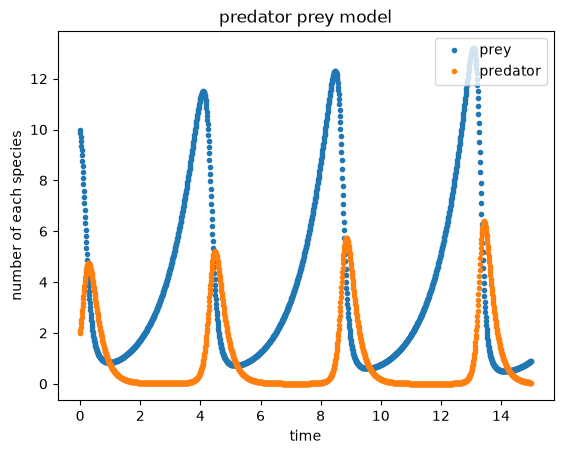

In [38]:
plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Let's think a bit about what this solution means, what is going on here?

What happens if we start with different initial conditions? Like more prey and less predators.

In [39]:
# initial conditions (initial populations):
x0 = 15. # initial prey amount
y0 = 0.001 # initial predator amount
t0 = 0.

In [40]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

In [41]:
# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

What happened?

Text(0.5, 1.0, 'predator prey model')

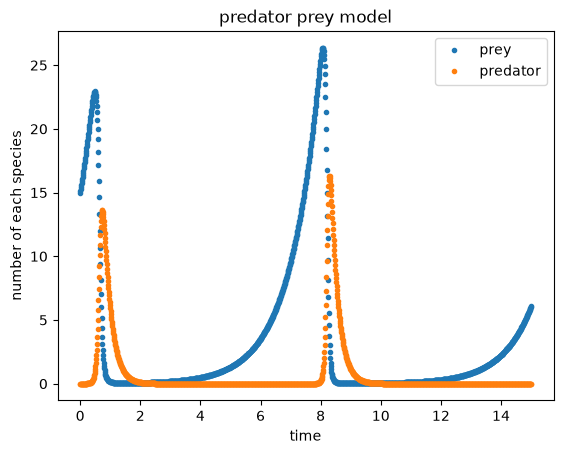

In [42]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What if we start with the same amount of prey and predators?

In [43]:
# set the parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

In [44]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [45]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

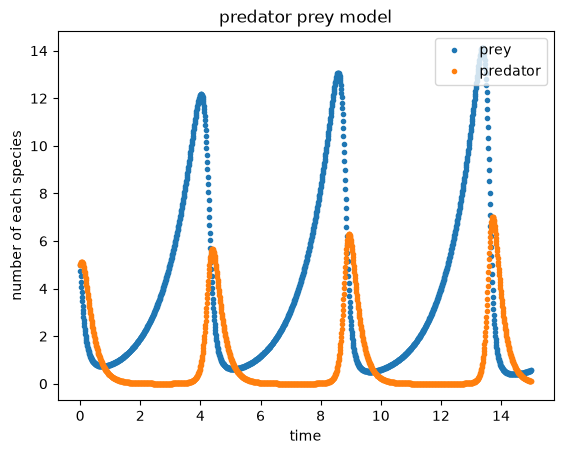

In [46]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

Text(0.5, 1.0, 'predator prey model')

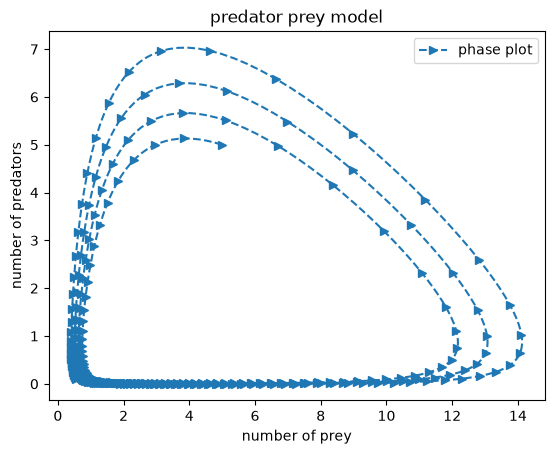

In [47]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

What happened?

Let's mess around with the model parameters. What if the prey grow faster?

In [48]:
# set the parameters
alpha = 10.
beta = 1.2
gamma = 4.
delta = 1.

In [49]:
# initial conditions (initial populations):
x0 = 5. # initial prey amount
y0 = 5 # initial predator amount
t0 = 0.

In [50]:
# initialize the array containing the solution for each time-step
u_euler = np.zeros((N, 2))

# imput initial conditions
u_euler[0] = np.array([x0, y0])

# use a for loop to call the function euler_step()
for n in range(N-1):
    u_euler[n+1] = euler_step(u_euler[n], f, dt)

Text(0.5, 1.0, 'predator prey model')

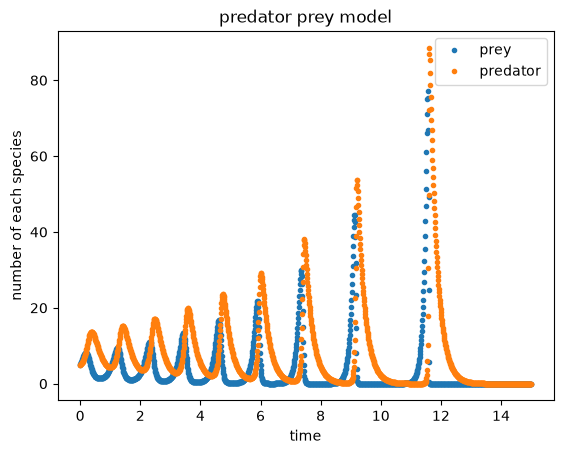

In [51]:
# break up the solutions for plotting
time = np.linspace(0.0, T,N)
x_euler = u_euler[:,0]
y_euler = u_euler[:,1]

plt.plot(time, x_euler, '.', label = 'prey ')
plt.plot(time, y_euler, '.', label = 'predator')
plt.legend(loc='upper right')
#labels
plt.xlabel("time")
plt.ylabel("number of each species")
#title
plt.title("predator prey model")

What happened?

### 12.2.3 System behavior

A better understanding of the system behavior can be obtained by a phase plot of the population of predators vs. the population of prey. It will tell us if the system sustains or collapses over time. For the choice of parameters $ \alpha, \beta, \gamma $ and $ \delta $ made above, we see that the maximum population of each species keeps increasing each cycle. You can read more about that in the Wikipedia link mentioned above.

Text(0.5, 1.0, 'predator prey model')

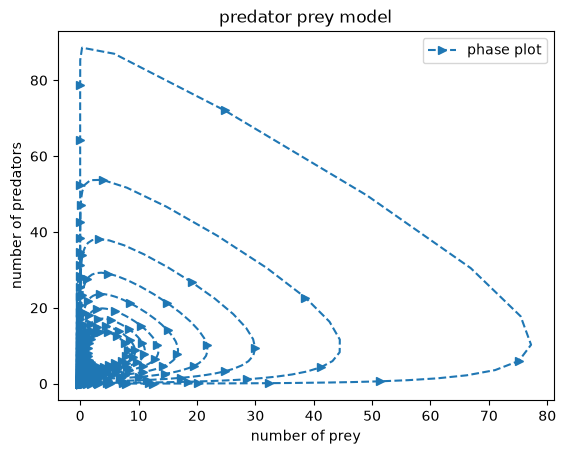

In [52]:
plt.plot(x_euler, y_euler, '-->', markevery=5, label = 'phase plot')
plt.legend(loc='upper right')
#labels
plt.xlabel("number of prey")
plt.ylabel("number of predators")
#title
plt.title("predator prey model")

# Lab 12.2

#### E.1 How does timestep affect the solution?
Modify the timestep (or time increment) dt. How does this affect your solutions? Plot both the timeseries and the phase plots. Try making dt 10 times bigger (dt = 0.1) and 10 times smaller. Describe what happens to your results. What happens if you make dt 100 times smaller?

dt = 0.1: first negative population at t = 6.30.
The plots for this run end at the last valid timestep.


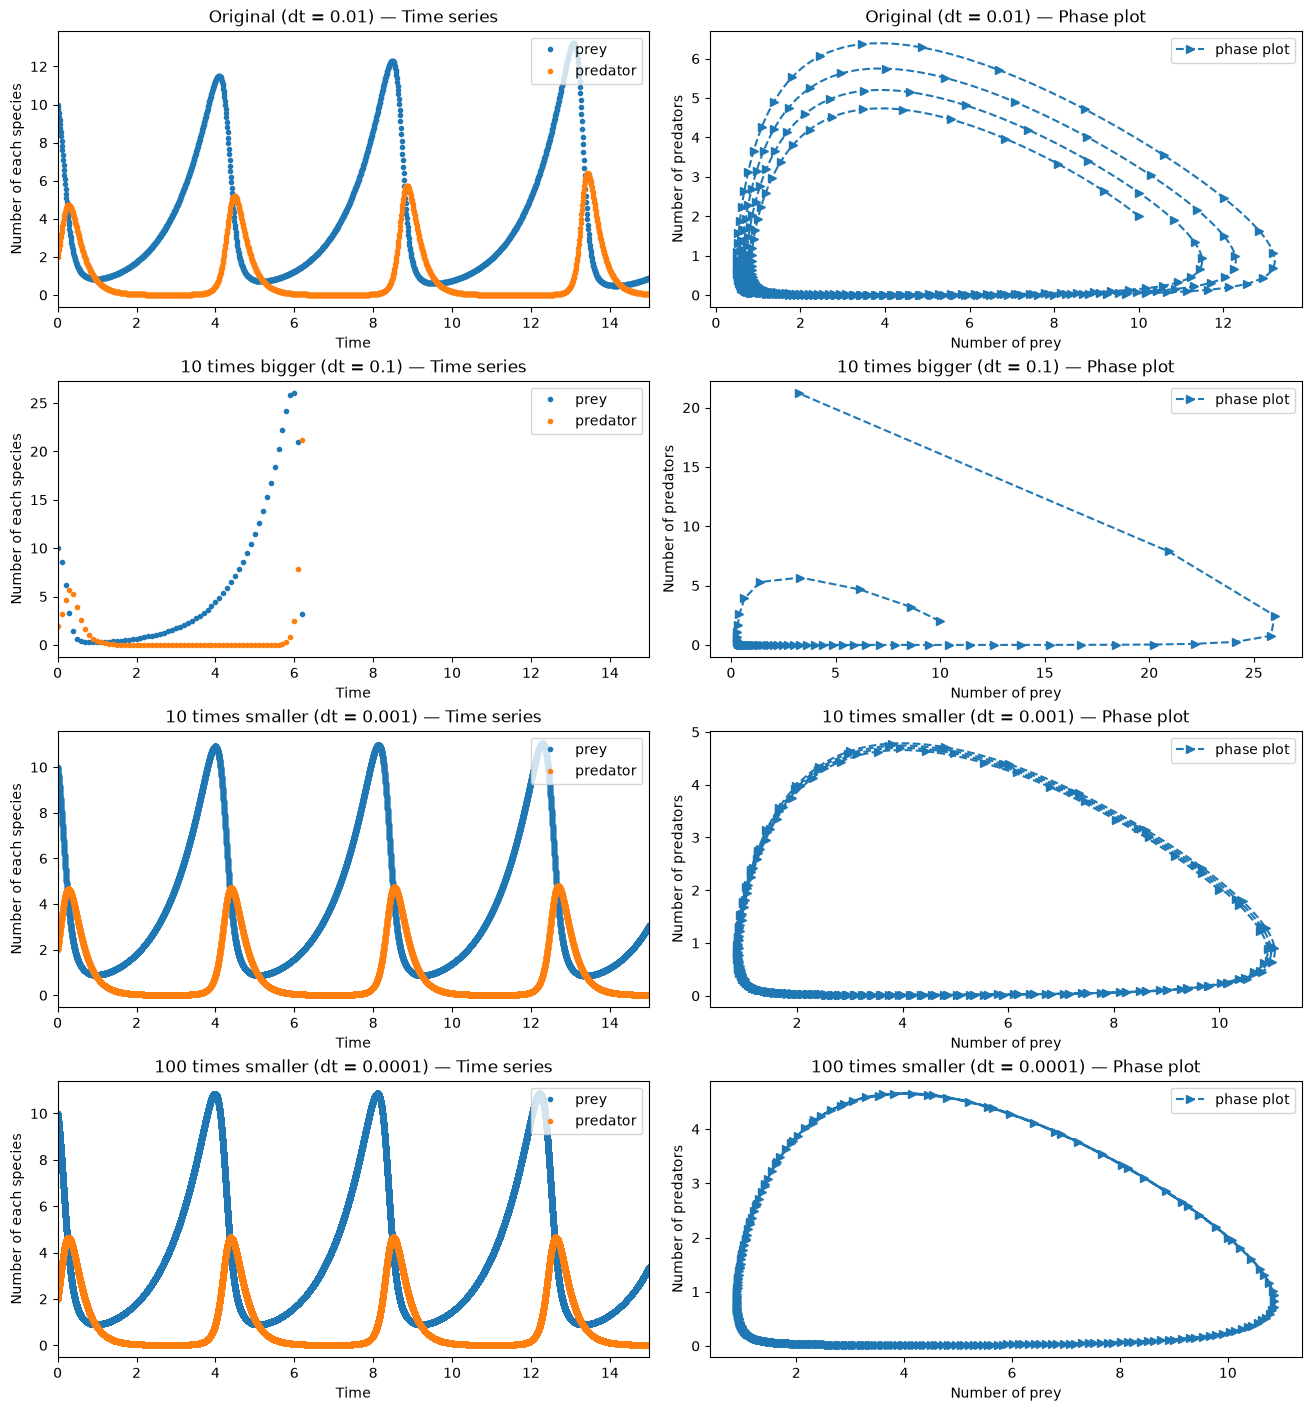

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# Original model parameters
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

# Original initial conditions and simulation length
x0 = 10.
y0 = 2.
T = 15.

# Lotka–Volterra equations
def f(u):
    x, y = u
    dxdt = x * (alpha - beta * y)
    dydt = -y * (gamma - delta * x)
    return np.array([dxdt, dydt])

# Forward Euler method
def euler_step(u, f, dt):
    return u + dt * f(u)

# Compare the original timestep with the three changes requested in E.1
timesteps = [0.01, 0.1, 0.001, 0.0001]
cases = ["Original", "10 times bigger", "10 times smaller", "100 times smaller"]

fig, axes = plt.subplots(4, 2, figsize=(13, 14), constrained_layout=True)

for row, dt in enumerate(timesteps):
    N = round(T / dt) + 1
    time = np.linspace(0, T, N)

    # Start each run with the same prey and predator populations
    u_euler = np.zeros((N, 2))
    u_euler[0] = [x0, y0]

    for n in range(N - 1):
        u_euler[n + 1] = euler_step(u_euler[n], f, dt)

        # Stop if a large timestep produces a negative population
        if np.any(u_euler[n + 1] < 0):
            print(f"dt = {dt}: first negative population at t = {time[n + 1]:.2f}.")
            print("The plots for this run end at the last valid timestep.")
            u_euler = u_euler[:n + 1]
            time = time[:n + 1]
            break

    x_euler = u_euler[:, 0]
    y_euler = u_euler[:, 1]

    # Left column: population versus time
    ax = axes[row, 0]
    ax.plot(time, x_euler, '.', label='prey')
    ax.plot(time, y_euler, '.', label='predator')
    ax.set_xlabel('Time')
    ax.set_ylabel('Number of each species')
    ax.set_title(f'{cases[row]} (dt = {dt}) — Time series')
    ax.set_xlim(0, T)
    ax.legend(loc='upper right')

    # Right column: predators versus prey
    # The original plot marks every 5 steps at dt = 0.01.
    # Keep that same time interval between markers for every run.
    marker_step = max(1, round(0.05 / dt))

    ax = axes[row, 1]
    ax.plot(x_euler, y_euler, '-->', markevery=marker_step, label='phase plot')
    ax.set_xlabel('Number of prey')
    ax.set_ylabel('Number of predators')
    ax.set_title(f'{cases[row]} (dt = {dt}) — Phase plot')
    ax.legend(loc='upper right')

plt.show()

With the original timestep of dt = 0.01, each predator peak follows a prey peak, but the peaks gradually grow taller and the phase plot spirals outward. Increasing the timestep to 0.1 makes this drift much stronger because each Euler step uses the current growth rates over a longer interval. The approximation becomes unreliable as the populations change rapidly near a peak.

Reducing the timestep to 0.001 gives more consistent peak heights, and the loops in the phase plot nearly overlap. At dt = 0.0001, the loops overlap even more closely and appear almost as a single closed curve. The prey still peak before the predators at these smaller timesteps. The feature that changes most is the outward drift, showing that the growing peaks in the original run come from accumulated numerical error.

#### E.2 Adding the steady state

The steady state(s) of the system are found by setting the population equations to zero, that is the solution to when the population is not changing. This is also called a "fixed point" of the equations, since if the populations start there they stay there, i.e. are fixed.

Find the steady states of the system using algebra. Plot the fixed point (steady state population) of the system on both the timeseries and phase space plots. Describe where the fixed point is in the phase space plot and plot it. What happens if you start at the steady state? What happens if you start near the steady state?

$\alpha x - \beta x y  = 0$

$\delta x y -\gamma y  = 0$



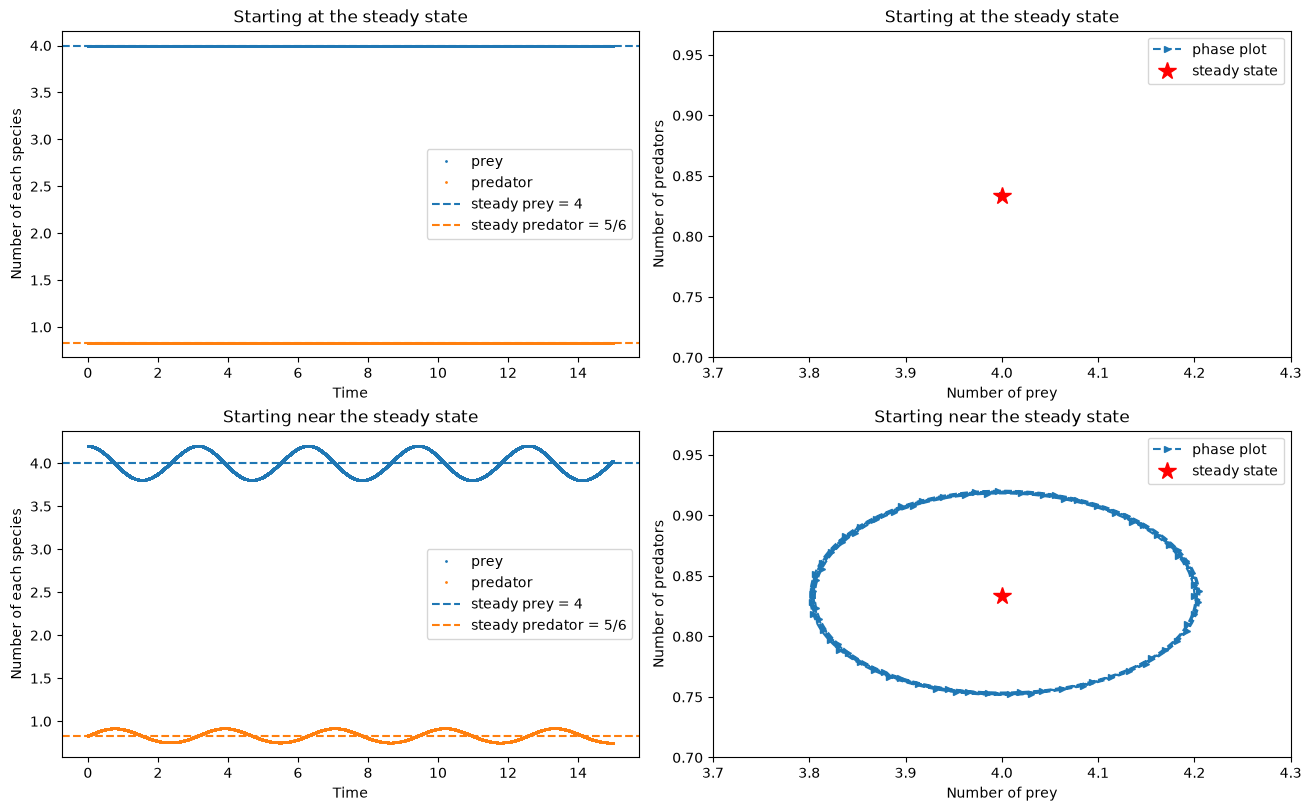

In [64]:
def f(u):
    x, y = u
    return np.array([x * (alpha - beta*y), -y * (gamma - delta*x)])

def euler_step(u, f, dt):
    return u + dt * f(u)

# Calculate the coexistence steady state
x_star = gamma / delta
y_star = alpha / beta

T = 15.
dt = 0.001
N = round(T / dt) + 1
time = np.linspace(0, T, N)

cases = [
    ("Starting at the steady state", x_star, y_star),
    ("Starting near the steady state", x_star + 0.2, y_star)
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

for row, (title, x0, y0) in enumerate(cases):
    u_euler = np.zeros((N, 2))
    u_euler[0] = [x0, y0]

    for n in range(N - 1):
        u_euler[n + 1] = euler_step(u_euler[n], f, dt)

    x_euler = u_euler[:, 0]
    y_euler = u_euler[:, 1]

    # Time series: each population has its own steady-state level
    ax = axes[row, 0]
    ax.plot(time, x_euler, '.', color='tab:blue', markersize=2, label='prey')
    ax.plot(time, y_euler, '.', color='tab:orange', markersize=2, label='predator')
    ax.axhline(x_star, color='tab:blue', linestyle='--', label='steady prey = 4')
    ax.axhline(y_star, color='tab:orange', linestyle='--', label='steady predator = 5/6')
    ax.set(xlabel='Time', ylabel='Number of each species', title=title)
    ax.legend(loc='center right')

    # Phase plot: the two steady-state populations form one point
    ax = axes[row, 1]
    ax.plot(x_euler, y_euler, '-->', markevery=200, markersize=4, label='phase plot')
    ax.plot(x_star, y_star, 'r*', markersize=13, label='steady state')
    ax.set(xlabel='Number of prey', ylabel='Number of predators', title=title, xlim=(3.7, 4.3), ylim=(0.70, 0.97))
    ax.legend(loc='upper right')

plt.show()

The coexistence fixed point is at \((4, 5/6)\), inside the loop on the phase plot. When I start exactly there, the time series shows two horizontal lines. Since the prey and predator populations keep the same values at every timestep, the entire phase plot reduces to one point. When I start nearby with 4.2 prey, the extra prey initially allow the predator population to grow. The prey then decline, followed by the predators, and the cycle repeats. The time series shows small oscillations around the two steady-state levels, and the phase plot traces a loop around the fixed point. In the exact model, this loop is closed. Any slight outward drift in the plotted loop comes from the forward Euler method.

#### E.3 A better algorithm
Do Exercise 1 again with a fourth order time stepping method called "Runge-Kutta 4" whose algorithm is given below. How do your answers differ? How does the dt, the timestep, affect your answer using this "higher order" algorithm?

In [56]:
def RK4(u,f,dt):
    # Runge Kutta 4th order method
    """Returns the solution at the next time-step using Runge Kutta fourth order (RK4) method.
    
    Parameters
    ----------
    u : array of float
        solution at the previous time-step.
    f : function
        function to compute the right hand-side of the system of equation.
    dt : float
        time-increment.
    
    Returns
    -------
    u_n_plus_1 : array of float
        approximate solution at the next time step.
    """
    #calculate slopes
    k1 = f(u)
    u1 = u + (dt/2.)*k1
    k2 = f(u1)
    u2 = u + (dt/2.)*k2
    k3 = f(u2)
    u3 = u + dt*k3
    k4 = f(u3)
    return u + (dt/6.)*(k1 + 2.*k2 + 2.*k3 + k4)

dt = 0.01     Max prey = 10.851282  Max predators = 4.648528
dt = 0.1      Max prey = 10.854141  Max predators = 4.649883
dt = 0.001    Max prey = 10.851347  Max predators = 4.648535
dt = 0.0001   Max prey = 10.851348  Max predators = 4.648535


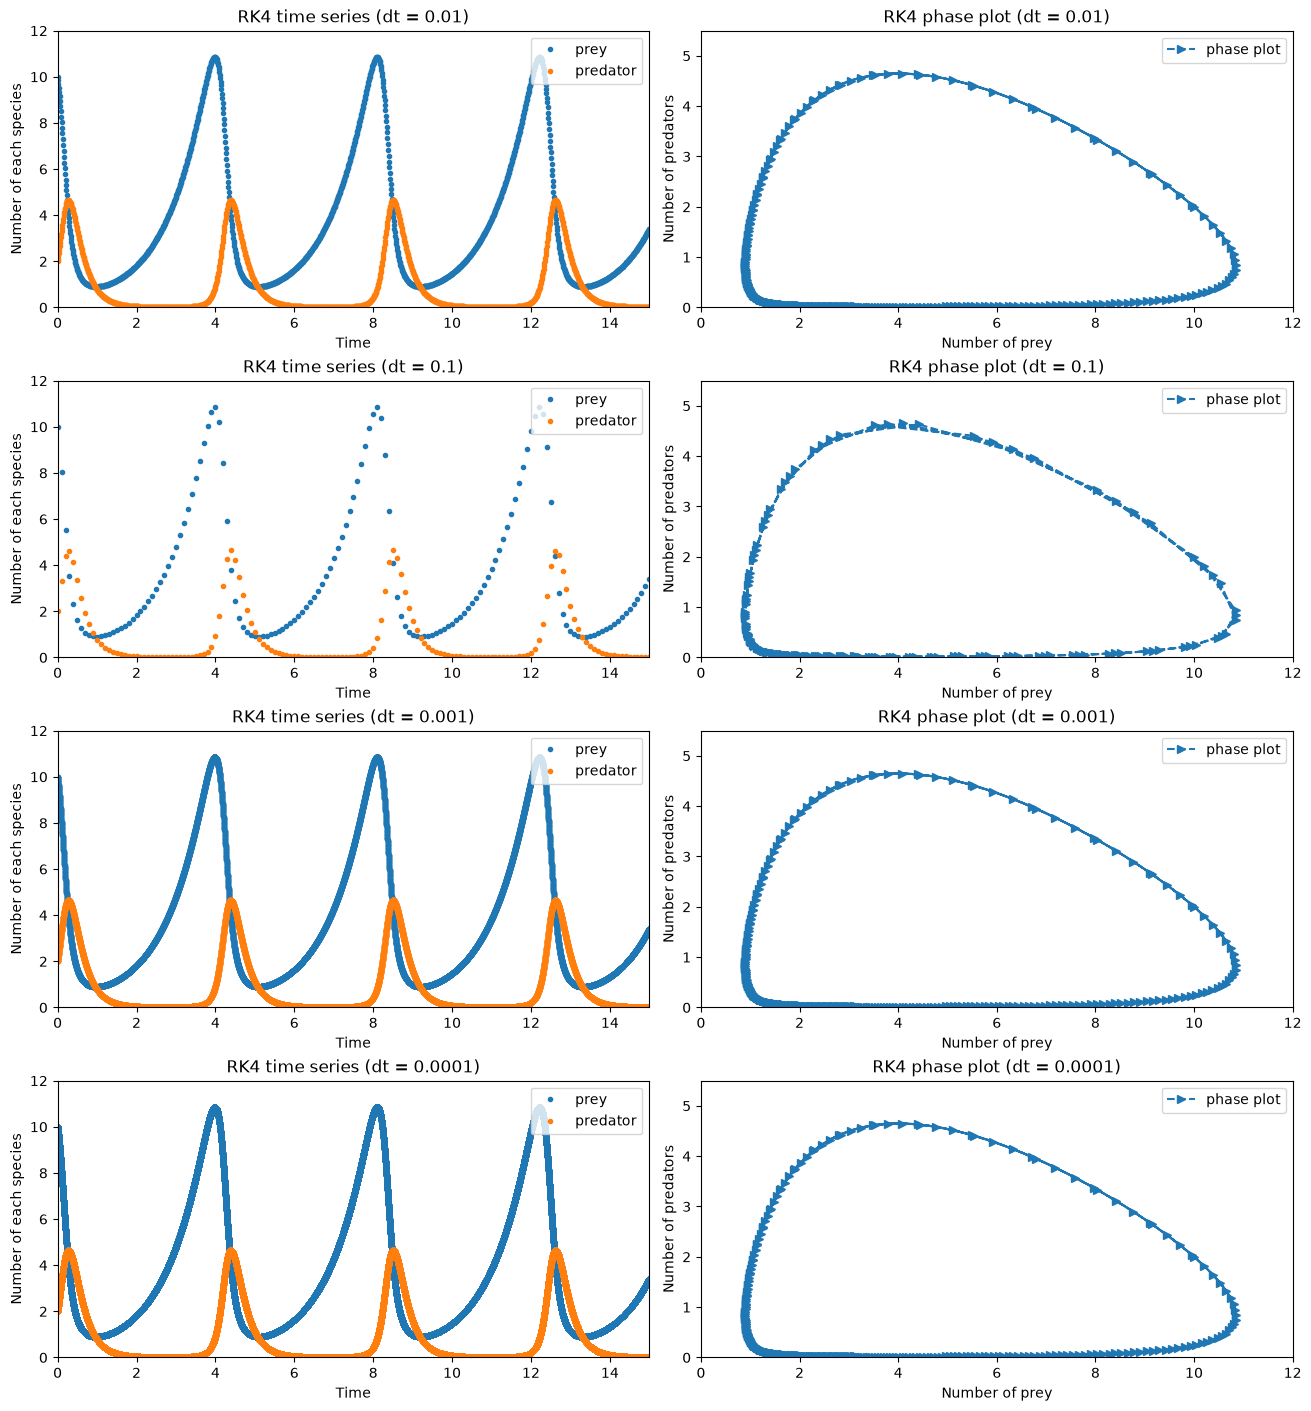

In [65]:
alpha = 1.
beta = 1.2
gamma = 4.
delta = 1.

x0 = 10.   # initial prey population
y0 = 2.    # initial predator population
T = 15.    # final time

# Lotka–Volterra equations
def f(u):
    x, y = u
    dxdt = x * (alpha - beta * y)
    dydt = -y * (gamma - delta * x)
    return np.array([dxdt, dydt])

# Fourth-order Runge–Kutta method
def RK4(u, f, dt):
    k1 = f(u)

    u1 = u + (dt / 2.) * k1
    k2 = f(u1)

    u2 = u + (dt / 2.) * k2
    k3 = f(u2)

    u3 = u + dt * k3
    k4 = f(u3)

    return u + (dt / 6.) * (k1 + 2*k2 + 2*k3 + k4)

# Original, 10 times bigger, 10 times smaller, and 100 times smaller
timesteps = [0.01, 0.1, 0.001, 0.0001]

fig, axes = plt.subplots(4, 2, figsize=(13, 14), constrained_layout=True)

for row, dt in enumerate(timesteps):
    N = round(T / dt) + 1
    time = np.linspace(0, T, N)

    # Restart each simulation with 10 prey and 2 predators
    u_rk4 = np.zeros((N, 2))
    u_rk4[0] = [x0, y0]

    for n in range(N - 1):
        u_rk4[n + 1] = RK4(u_rk4[n], f, dt)

    x_rk4 = u_rk4[:, 0]
    y_rk4 = u_rk4[:, 1]


    ax = axes[row, 0]
    ax.plot(time, x_rk4, '.', label='prey')
    ax.plot(time, y_rk4, '.', label='predator')
    ax.set(xlabel='Time', ylabel='Number of each species', title=f'RK4 time series (dt = {dt})', xlim=(0, T), ylim=(0, 12))
    ax.legend(loc='upper right')

    ax = axes[row, 1]
    marker_step = max(1, round(0.05 / dt))
    ax.plot(x_rk4, y_rk4, '-->', markevery=marker_step, label='phase plot')
    ax.set(xlabel='Number of prey', ylabel='Number of predators', title=f'RK4 phase plot (dt = {dt})', xlim=(0, 12), ylim=(0, 5.5))
    ax.legend(loc='upper right')

    print(f"dt = {dt:<7}  Max prey = {x_rk4.max():.6f}  "f"Max predators = {y_rk4.max():.6f}")

plt.show()

With RK4, the prey population peaks before the predator population at all four timesteps. Unlike the forward Euler result in E.1, the RK4 peaks stay nearly the same height from one cycle to the next. This difference is easiest to see in the phase plots, where successive RK4 loops nearly overlap.

At the largest timestep (`dt = 0.1`), the dots in the time series are farther apart and the phase curve looks less smooth, but the model still captures the cycle. Reducing `dt` to `0.01` gives a smoother curve. Reducing it further to `0.001` and `0.0001` produces almost no visible change. For both of these smaller timesteps, the maximum prey and predator populations are approximately 10.851 and 4.649. RK4 is less sensitive to timestep size in this experiment because it uses four slope estimates to update the populations at each step.

#### E.4 Exploring parameter space
Vary the interactions between species by changing $\alpha, \beta, \gamma, \delta$ and see what happens to the population evolution as well as phase plots. How does changing each parameter individually affect the system?

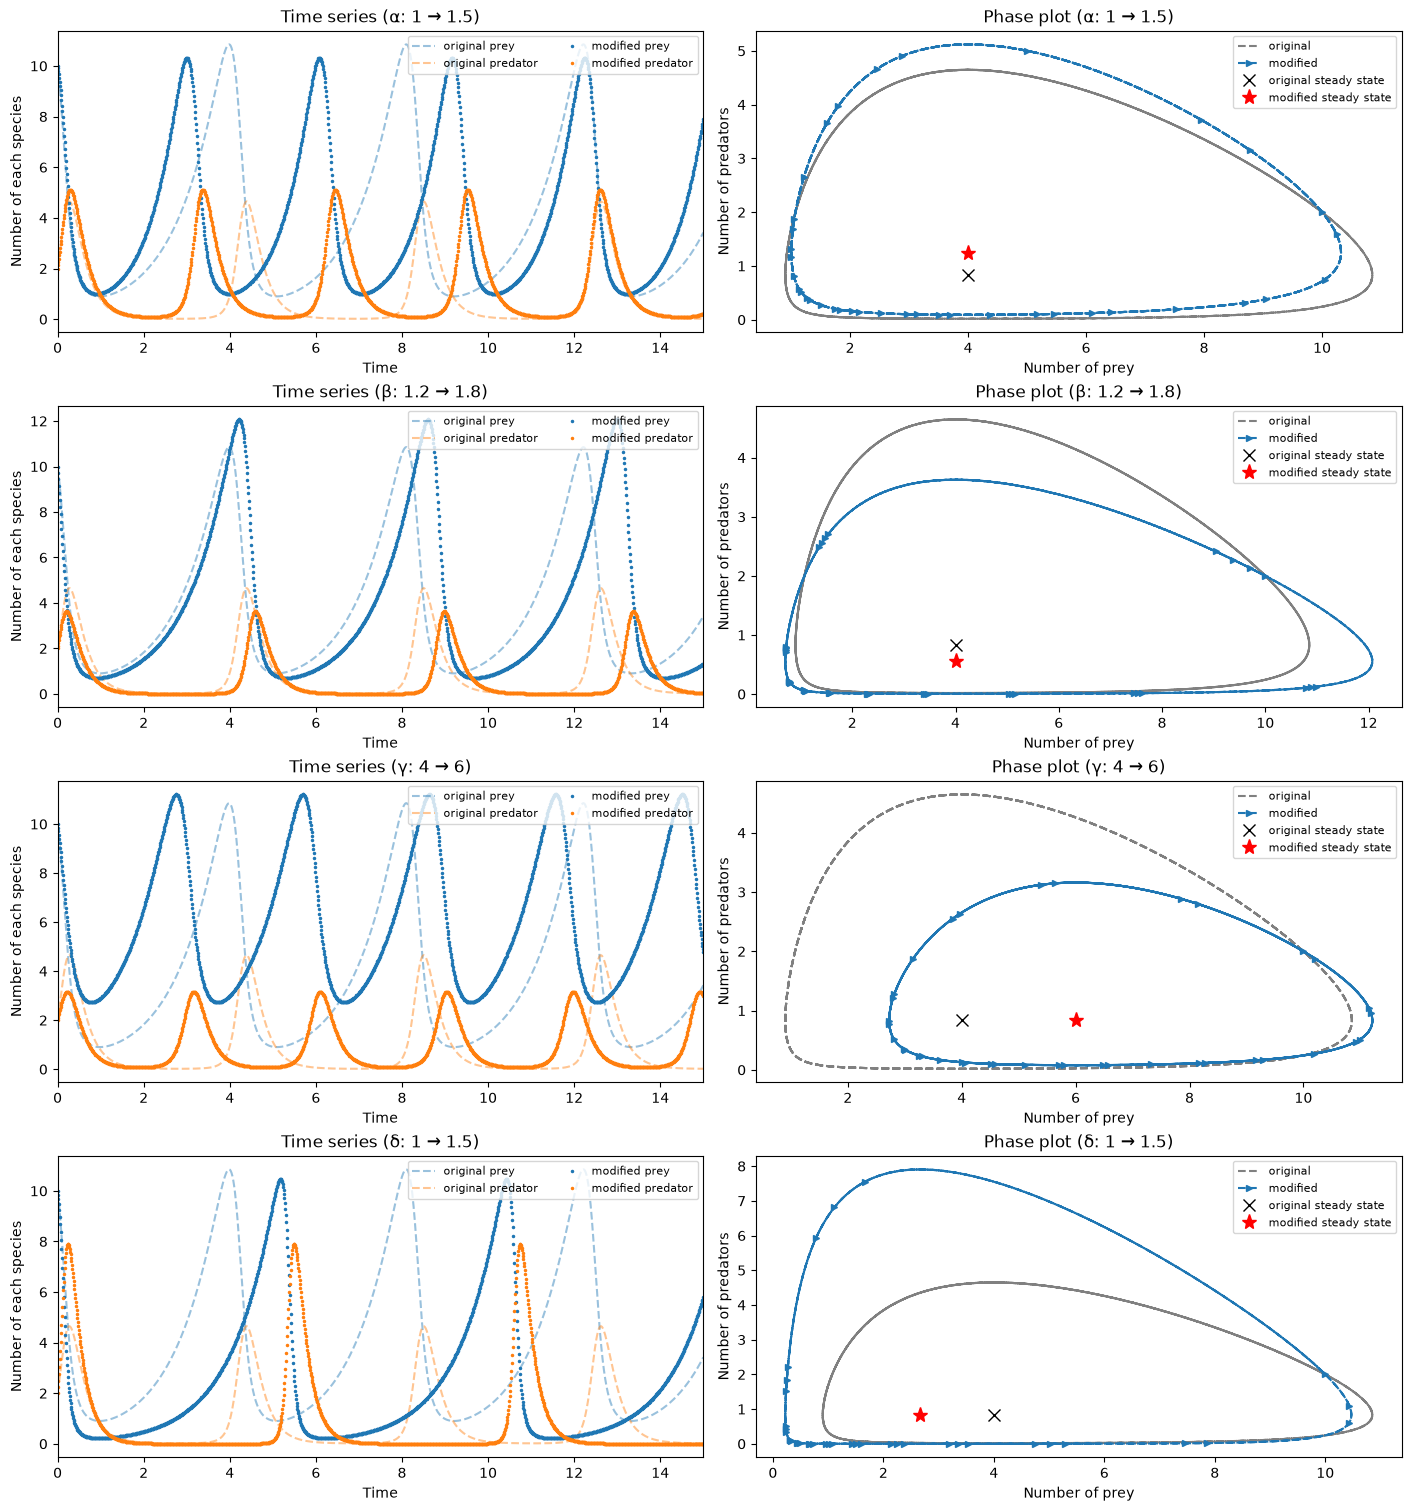

In [66]:
# Original model parameters
original = {'alpha': 1.0, 'beta': 1.2, 'gamma': 4.0, 'delta': 1.0}

x0 = 10.
y0 = 2.
T = 15.
dt = 0.01
N = round(T / dt) + 1
time = np.linspace(0, T, N)

# Lotka–Volterra equations
def f(u, alpha, beta, gamma, delta):
    x, y = u
    dxdt = x * (alpha - beta * y)
    dydt = y * (delta * x - gamma)
    return np.array([dxdt, dydt])

# Fourth-order Runge–Kutta method from E.3
def RK4(u, f, dt):
    k1 = f(u)
    k2 = f(u + (dt / 2.) * k1)
    k3 = f(u + (dt / 2.) * k2)
    k4 = f(u + dt * k3)
    return u + (dt / 6.) * (k1 + 2*k2 + 2*k3 + k4)

# Run the model with one set of parameters
def simulate(params):
    def rates(u):
        return f(u, **params)

    u_rk4 = np.zeros((N, 2))
    u_rk4[0] = [x0, y0]

    for n in range(N - 1):
        u_rk4[n + 1] = RK4(u_rk4[n], rates, dt)

    return u_rk4[:, 0], u_rk4[:, 1]

# Calculate the original solution once for comparison
x_original, y_original = simulate(original)
symbols = {'alpha': 'α', 'beta': 'β', 'gamma': 'γ', 'delta': 'δ'}

fig, axes = plt.subplots(4, 2, figsize=(14, 15), constrained_layout=True)

for row, name in enumerate(original):
    # Start from the original values each time so changes do not accumulate
    params = original.copy()
    params[name] *= 1.5

    x_rk4, y_rk4 = simulate(params)
    change = f"{symbols[name]}: {original[name]:g} → {params[name]:g}"

    # Left: compare the original and modified time series
    ax = axes[row, 0]
    ax.plot(time, x_original, '--', color='tab:blue', alpha=0.45, label='original prey')
    ax.plot(time, y_original, '--', color='tab:orange', alpha=0.45, label='original predator')
    ax.plot(time, x_rk4, '.', color='tab:blue', markersize=3, label='modified prey')
    ax.plot(time, y_rk4, '.', color='tab:orange', markersize=3, label='modified predator')
    ax.set(xlabel='Time', ylabel='Number of each species', title=f'Time series ({change})', xlim=(0, T))
    ax.legend(loc='upper right', ncol=2, fontsize=8)

    # Right: compare phase trajectories and mark both steady states
    ax = axes[row, 1]
    ax.plot(x_original, y_original, '--', color='gray', label='original')
    ax.plot(x_rk4, y_rk4, '-->', color='tab:blue', markevery=40, markersize=4, label='modified')
    ax.plot(original['gamma'] / original['delta'], original['alpha'] / original['beta'], 'kx', markersize=8, label='original steady state')
    ax.plot(params['gamma'] / params['delta'], params['alpha'] / params['beta'], 'r*', markersize=11, label='modified steady state')
    ax.set(xlabel='Number of prey', ylabel='Number of predators', title=f'Phase plot ({change})')
    ax.legend(loc='upper right', fontsize=8)

plt.show()

I increased each parameter by 50% while keeping the other three at their original values. In the original model, the coexistence steady state is 4 prey and approximately 0.833 predators. The two coordinates of this point are $x^*=\gamma/\delta$ and $y^*=\alpha/\beta$, which explain the direction of each shift in the phase plots.

- **Increasing $\alpha$ from 1 to 1.5** increases the prey reproduction rate. At the start of this simulation, predation still exceeds reproduction, but the prey decline more slowly than in the original run. Faster reproduction allows the prey to support a larger predator population at equilibrium. The fixed point moves **up**, from $(4, 0.833)$ to $(4, 1.25)$.

- **Increasing $\beta$ from 1.2 to 1.8** increases prey loss from encounters with predators. The prey therefore decline more sharply at the start. Fewer predators are needed to balance prey reproduction, so the fixed point moves **down**, from $(4, 0.833)$ to approximately $(4, 0.556)$.

- **Increasing $\gamma$ from 4 to 6** increases the predator death rate. With 10 prey initially available, the predators still increase at first, but more slowly. Their population now starts declining when prey fall below 6, compared with 4 in the original model. The fixed point moves **right**, from $(4, 0.833)$ to $(6, 0.833)$.

- **Increasing $\delta$ from 1 to 1.5** increases predator population growth for the same number of predator–prey encounters. The predators increase more rapidly at the start and can sustain their population with fewer prey. The fixed point moves **left**, from $(4, 0.833)$ to approximately $(2.667, 0.833)$.

In all four runs, the populations continue to cycle. The time series show how the timing and height of the peaks change, while the phase plots show the loop each pair of populations traces around its new fixed point.

#### E.5 (Advanced, required for grad students)
Modify the differential equations to include other types of interactions. See advanced predator prey example link at the top for ideas. You might add in a self-eating (i.e. $-ay^2$) term into the predator equation. Or do the zombie apocalypse example linked above.

No initial dead, no births: zombies outnumber humans at day 4.57
5 initial dead, no births: zombies outnumber humans at day 3.27
5 initial dead, 10 births per day: zombies outnumber humans at day 3.18


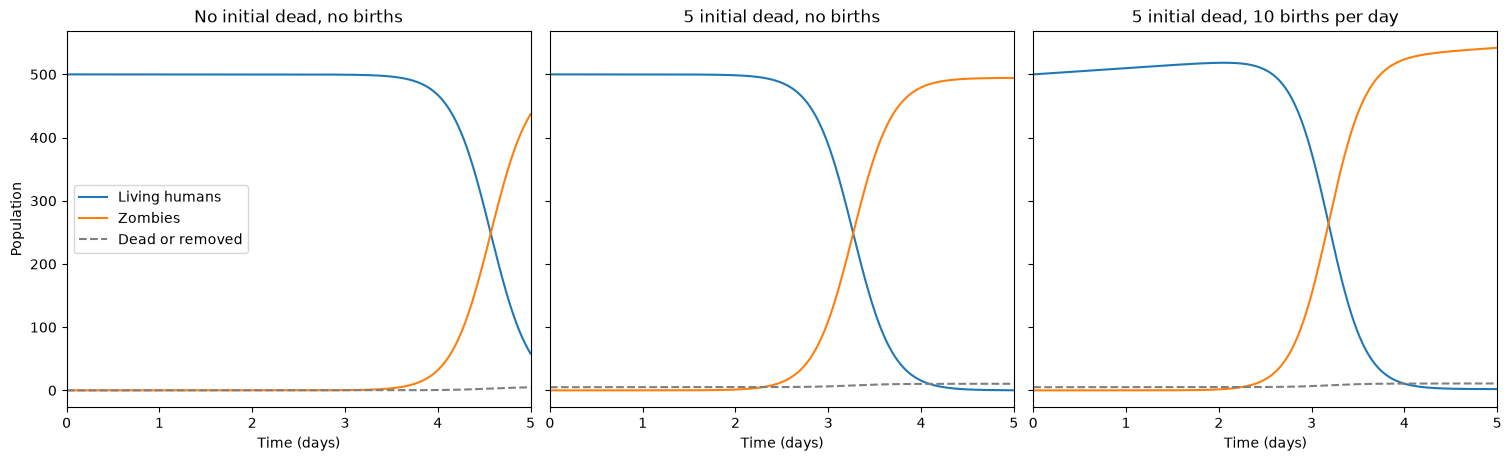

In [62]:
from scipy.integrate import odeint

# Model parameters from the SciPy Cookbook
d = 0.0001   # natural death rate
B = 0.0095   # infection rate through human-zombie encounters
G = 0.0001   # resurrection rate
A = 0.0001   # zombie removal rate through human-zombie encounters

def zombie_model(u, t, P):
    S, Z, R = u

    # Rates at which individuals move between populations
    infections = B * S * Z
    natural_deaths = d * S
    resurrections = G * R
    zombie_removals = A * S * Z

    # Change in each population per day
    dSdt = P - infections - natural_deaths
    dZdt = infections + resurrections - zombie_removals
    dRdt = natural_deaths + zombie_removals - resurrections

    return [dSdt, dZdt, dRdt]

# All three scenarios begin with 500 living humans and zero zombies
S0 = 500
Z0 = 0
time = np.linspace(0, 5, 1000)

# Each scenario specifies its title, initial dead population, and births per day
scenarios = [
    ('No initial dead, no births', 0, 0),
    ('5 initial dead, no births', 5, 0),
    ('5 initial dead, 10 births per day', 5, 10)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5),
                         sharex=True, sharey=True, constrained_layout=True)

for ax, (title, R0, P) in zip(axes, scenarios):
    solution = odeint(zombie_model, [S0, Z0, R0], time, args=(P,))

    S = solution[:, 0]
    Z = solution[:, 1]
    R = solution[:, 2]

    ax.plot(time, S, color='tab:blue', label='Living humans')
    ax.plot(time, Z, color='tab:orange', label='Zombies')
    ax.plot(time, R, '--', color='tab:gray', label='Dead or removed')
    ax.set_title(title)
    ax.set_xlabel('Time (days)')
    ax.set_xlim(0, 5)

    # First plotted time when zombies outnumber living humans
    crossing = np.flatnonzero(Z > S)
    if crossing.size:
        print(f'{title}: zombies outnumber humans at day {time[crossing[0]]:.2f}')

axes[0].set_ylabel('Population')
axes[0].legend()
plt.show()

I modified the model to track three populations: living humans ($S$), zombies ($Z$), and dead or removed individuals ($R$). The equations are

$$
\frac{dS}{dt}=P-BSZ-dS,\qquad
\frac{dZ}{dt}=BSZ+GR-ASZ,\qquad
\frac{dR}{dt}=dS+ASZ-GR.
$$

An infection ($BSZ$) transfers one individual from the living population to the zombie population. Natural deaths ($dS$) and zombie removals ($ASZ$) add individuals to the removed population. Resurrection ($GR$) allows individuals to move from that group back into the zombie population.

In the first scenario, both the zombie and removed populations start at zero. The outbreak takes time to develop because natural deaths must first supply the removed population before resurrection can produce zombies. Zombies outnumber living humans at approximately day **4.57**. Starting with five dead individuals allows resurrection to begin immediately, moving the crossover earlier to day **3.27**. Adding 10 births per day moves the crossover slightly earlier again, to day **3.18**, because the additional susceptible humans also increase the infection term $BSZ$ once zombies are present. Across all three five-day simulations, the living and zombie curves cross once, unlike the repeated cycles in the predator–prey model.